## Homework 4 - Analysis Using Hotelling's $T^2$ and Multiple Stream Process Control Charts
### Dr. Austin Brown
### Kennesaw State University

**DUE: November 20, 2026 via D2L**

## Instructions:

You are the director of The Owl's Nest, a psychological services program at a local university that employs a team of four Clinical Psychology PhD students to offer counseling services to the campus community at a steep discount. When a new client comes in, they commit to biweekly sessions for at least one semester. At the start of each session, the client completes a brief survey assessing depressive symptoms using Likert-scale items (e.g., "How much do you agree with this statement, on a scale from 1 (strongly disagree) to 5 (strongly agree)?"). The total score ranges from 20 to 100, with higher scores indicating more severe depressive symptoms.

If a counselor's client scores begin trending upward over time, that may indicate a need for you, as the director, to step in -- whether by providing additional training and supervision, or by referring a client to a higher level of care. Because all four counselors work in the same training program, share office space and supervision, and often see clients during the same high-stress points in the academic calendar (midterms, finals), you suspect their clients' scores may be correlated with one another from week to week, rather than behaving as four completely independent processes.

To monitor this, you perform an initial Phase I analysis, jointly monitoring the scores of all four counselors across the 16-week fall semester, taking a sample of 5 clients per week for each counselor. After confirming statistical control, you'll monitor the subsequent 16-week spring semester (Phase II) to determine whether anything has changed.

## Key Specifications

| Quantity | Value |
|---|---|
| Quality characteristic | Total depressive-symptom survey score (20-100 scale) |
| Number of counselors (streams) | 4 |
| Clients sampled per counselor per week (n) | 5 |
| Phase I weeks (m) | 16 (fall semester) |
| Phase II weeks (m) | 16 (spring semester) |
| Control Chart for Each Stream design value | $L = 3.46$ |

In [1]:
## Define & Measure
## Clone your forked repository to Colab ##

## Specify your GitHub username:
user_name <- "garrettspringsted"

## Specify the repository:
repo_name <- "STAT-7110-Quality-Control"

## Set the web address to your forked repository:
repo_address <- paste0(
  "https://github.com/",
  user_name,
  "/",
  repo_name,
  ".git"
)

## Check to see if repo is already cloned to Colab, and if not, clone repo:
if (!dir.exists(repo_name)) {
  system(paste("git clone", repo_address))
} else {
  print("Repository already cloned to Colab.")
}
## Set working drive to today's lecture:

setwd("/content/STAT-7110-Quality-Control/Assignments/HW4")
getwd()
list.files()

[1] "/content/STAT-7110-Quality-Control/Assignments/HW4"

[1] "Counselling_PhaseI.xlsx"  "Counselling_PhaseII.xlsx"
[3] "STAT-7110-HW4.ipynb"



### Q1: Briefly describe the purpose of this analysis
### A1: The purpose of this analysis is to monitor depressive symptom scores across four counselors using Hotelling $T^2$ and multiple-stream process control charts. Phase 1 will be used to establish statistical control during the fall semester, while Phase 2 will determine whether the process remains in control suring the spring semester. I want to identify unusual increases or trends on depressive symptom scores, determine whether changes are occuring across all counselors or within individual streams, and identify when addition supervision, training, or intervention may be necessary.


### Q2: Identify the quality characteristic being monitored, and classify its measurement scale. Why might it be reasonable to suspect that the four counselors' weekly scores are correlated with one another, rather than fully independent?
### A2: The quality characterisitic being monitored is the clients depressive symptom scores measured on a scale of 10-100. The individual survey items use an ordinal Likert scale, while the total scores are treated as quantitative measurements for the control chart analysis. It is reasonable to suspect that the four counselors' weekly scores are correlated because they work within the same training program, share office space and supervision, and see clients during similar periods of academic stress, such as midterms and finals. These shared factors may cause depressive symptoms to increase or decrease across multiple counselors during the same weeks, rather than behaving as fully independent processes.



### Q3: Given your answer to Q2, briefly explain why it might be reasonable to treat this scenario as a **multivariate process** (suggesting a Hotelling's $T^2$ chart) rather than a **multiple stream process** (suggesting the Control Chart for Each Stream technique). Under what different assumption would the opposite framing make more sense?
###A3: I belive it is reasonable to treat this as a multivariate process because the four counselors' weekly scores may be correlated due to shared supervision, training, and academic pressures based around the time of year. A Hotelling's $T^2$ chart allows us to monitor the counselors' scores jointly while accounting for the correlation between them.
### A multiple stream process would make sense if we assume the four counselors operated as independent processes, each measuring the same quality characteristic. Under this assumption, the Control Chart for Each Stream technique would allow us to monitor each counselor individually and identify which streams may be out of control.


## Analyze

### Q4: Read the Phase I data (`Counselling_PhaseI.xlsx`) into R as a list, one data frame per counselor (HINT: use `qcc::mqcc`, and make sure to remove the `Week` column from each data frame, possibly using `lapply`). Construct a Phase I Hotelling's $T^2$ chart. Do we have evidence of statistical control? Why or why not?

### A4:The Phase 1 Hotelling's $T^2$ chart gives us evidence that the process is in statistical control. All 16 weekly observation fall withing the control limits(LCL=0,UCL=14.13324), with no points exceeding the UCL. This sugests that there is no evidence of speicla cause variation during the fall semeser. The process also appears stable enough to establish a baseline for Phase 2.

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Package 'qcc' version 2.7

Type 'citation("qcc")' for citing this R package in publications.



List of 1
 $ Counselor1: tibble [16 × 5] (S3: tbl_df/tbl/data.frame)
  ..$ Client1: num [1:16] 40 52.4 43.7 64.2 40.5 ...
  ..$ Client2: num [1:16] 46.5 51.3 43 44.7 43.9 ...
  ..$ Client3: num [1:16] 38.3 45.6 50.6 50.5 54.4 ...
  ..$ Client4: num [1:16] 57.8 29.1 49.5 45.2 32.8 ...
  ..$ Client5: num [1:16] 47.6 50 39.5 39 49.8 ...


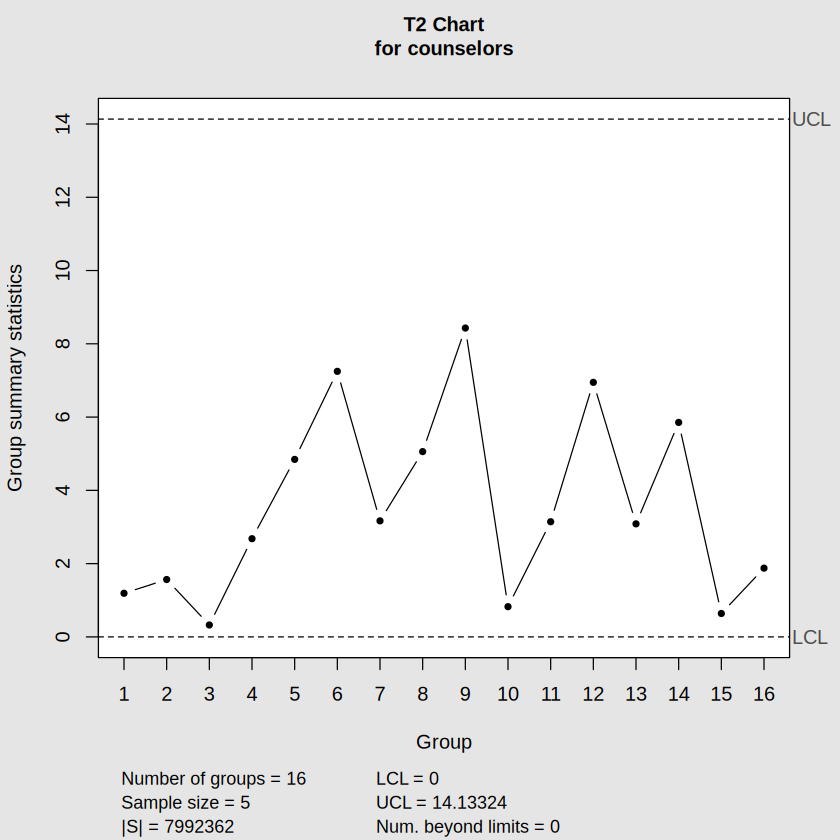

In [13]:
## Q4 Code ##
install.packages("qcc", repos = "https://cloud.r-project.org")
library(readxl)
library(dplyr)
library(qcc)
#Read in Phase 1 Counselling Data as List#

#Sheet Names#
sheetnames<- excel_sheets("Counselling_PhaseI.xlsx")
counselors<- lapply(sheetnames, FUN=function(x){
    d<- read_xlsx("Counselling_PhaseI.xlsx", sheet=x) %>%
    dplyr::select(-Week)

    return(d)
})

names(counselors) <-paste("Counselor", 1:4, sep="")

counselors["Counselor1"] |> glimpse()

## mqcc to Plot Chart ##

t2 <- mqcc(counselors, type = 'T2')

### Q5: Report the sample mean vector and sample variance-covariance matrix from Q4.

In [16]:
## Q5 Code ##
t2$center
t2$cov

Counselor1 Counselor2 Counselor3 Counselor4 
  45.34275   46.00288   45.28650   45.45975

,Counselor1,Counselor2,Counselor3,Counselor4
Counselor1,64.94685,25.20394,18.73784,28.36822
Counselor2,25.20394,63.96758,30.76070,26.36930
Counselor3,18.73784,30.76070,67.29034,14.95226
Counselor4,28.36822,26.36930,14.95226,60.67095


### Q6: Read the Phase II data (`Counselling_PhaseII.xlsx`) into R the same way. Using the mean vector and covariance matrix from Q5, construct a Phase II Hotelling's $T^2$ chart. Do we still have evidence of statistical control? If not, generate individual univariate Shewhart $\bar{X}$ and $s$ charts (using the appropriate mean and standard deviation from Phase I) to determine which counselor(s) may have out-of-control scores.

###A6: The Phase 2 Hotelling's $T^2$ chart indicated that the process is no longer in control. Using the Phase 1 mean vector and variance-covariance matrix, 11 of the 16 weekly observatios exceed the upper prediction linit of 16.01768. This provides evidence of special cause variation during the spring semester.

### The individual Shewhart X-bar and s charts suggest that counselor 3 is primarily responsible for the out-of-control process. Counselor 3's X-bar chart shows 10 run rule violations, indicating a sustained increase in average depressive symptom scores. Additionally, the s chart shows one observation exceeding the upper control limit during Week 9, suggesting increased variability in client scores. Counselors 1, 2, and 3 show no violation in either chart.

List of 1
 $ Counselor1: tibble [16 × 5] (S3: tbl_df/tbl/data.frame)
  ..$ Client1: num [1:16] 55.5 50.9 24.3 51.1 53.6 ...
  ..$ Client2: num [1:16] 57 36.5 55.5 53.9 60.2 ...
  ..$ Client3: num [1:16] 51.5 47 39.9 37.6 40.2 ...
  ..$ Client4: num [1:16] 30 42.7 41.6 46.3 41.9 ...
  ..$ Client5: num [1:16] 48.9 26.9 43.6 54.2 41.7 ...


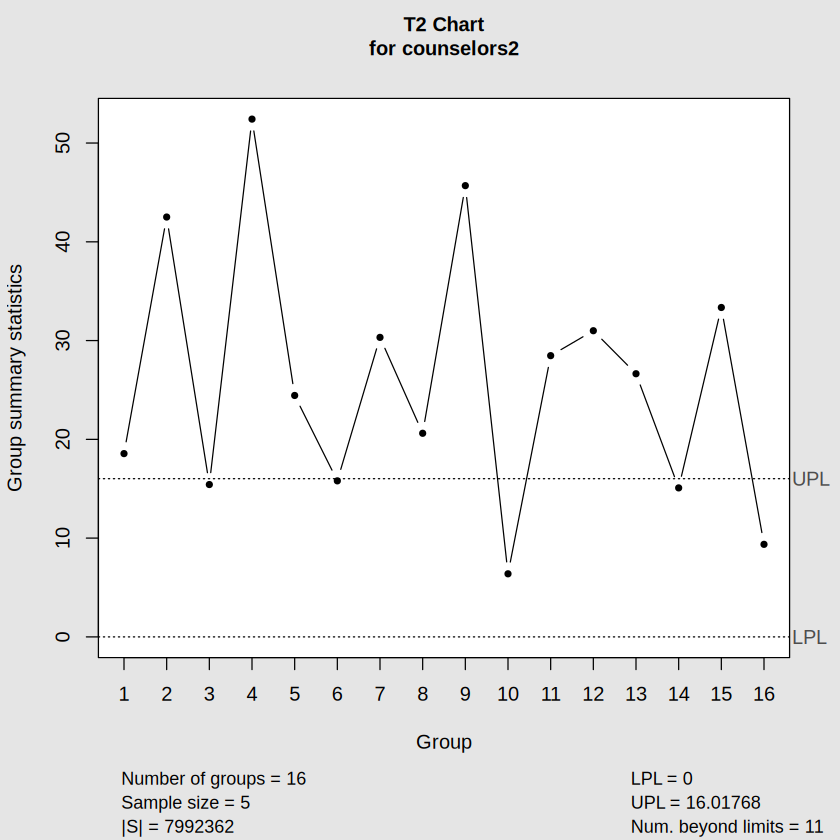

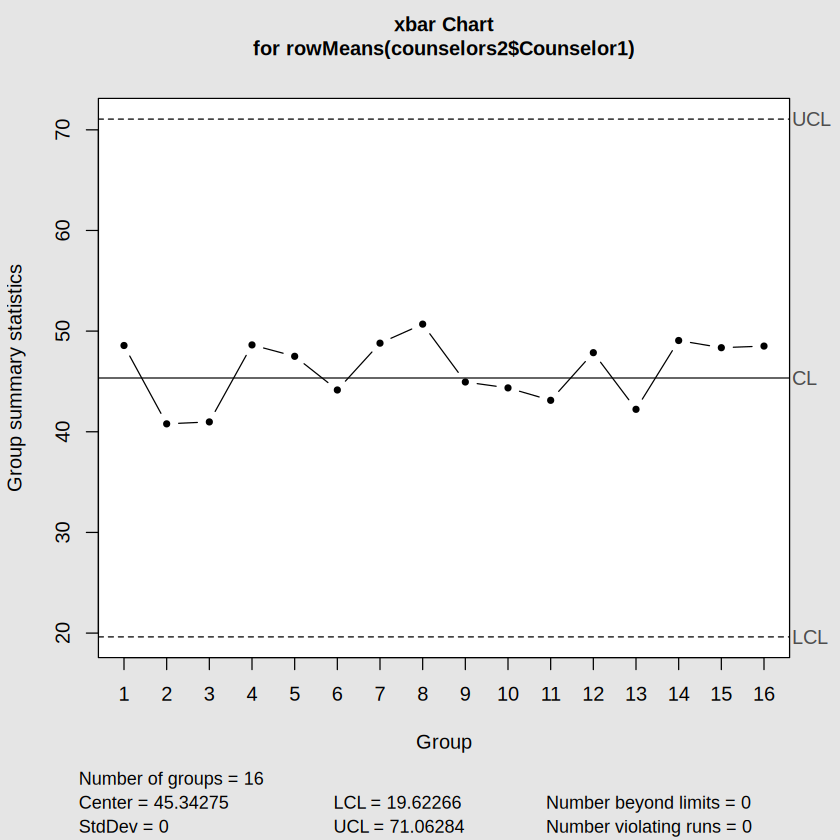

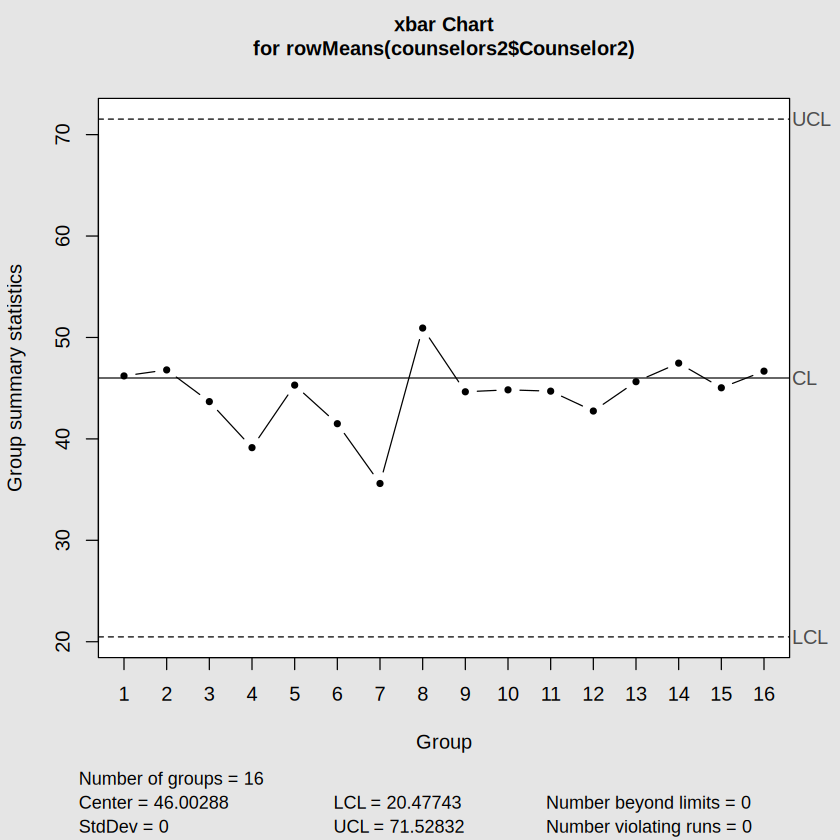

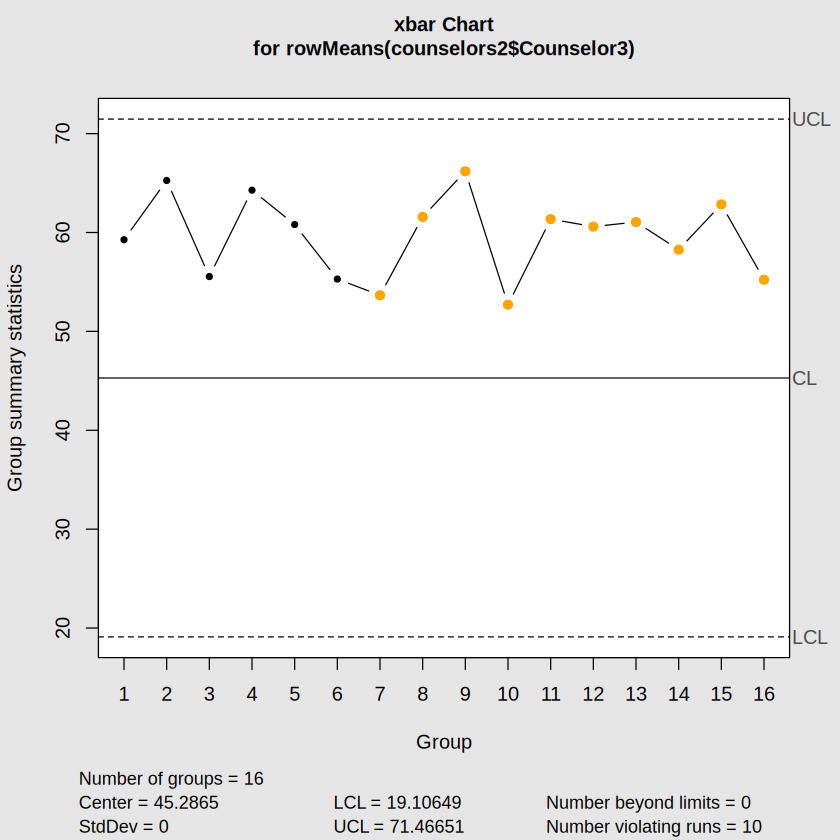

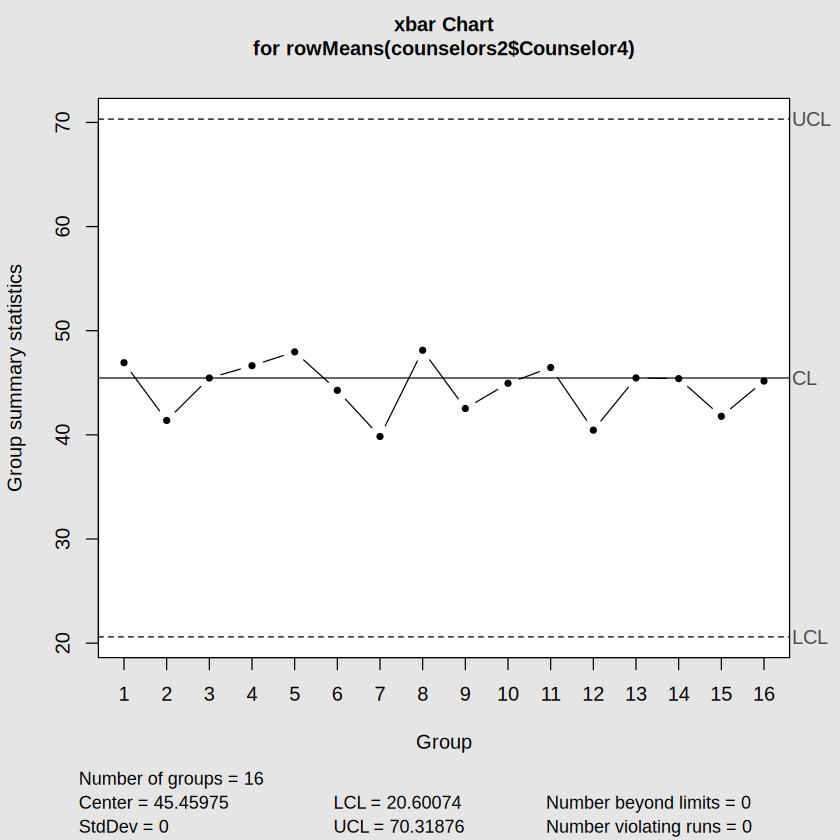

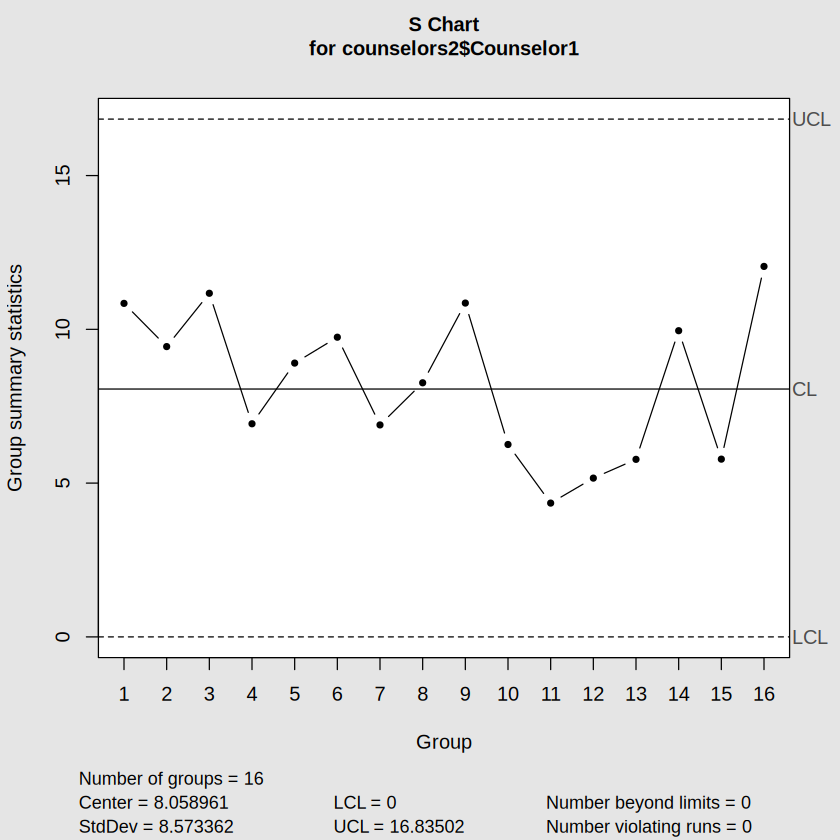

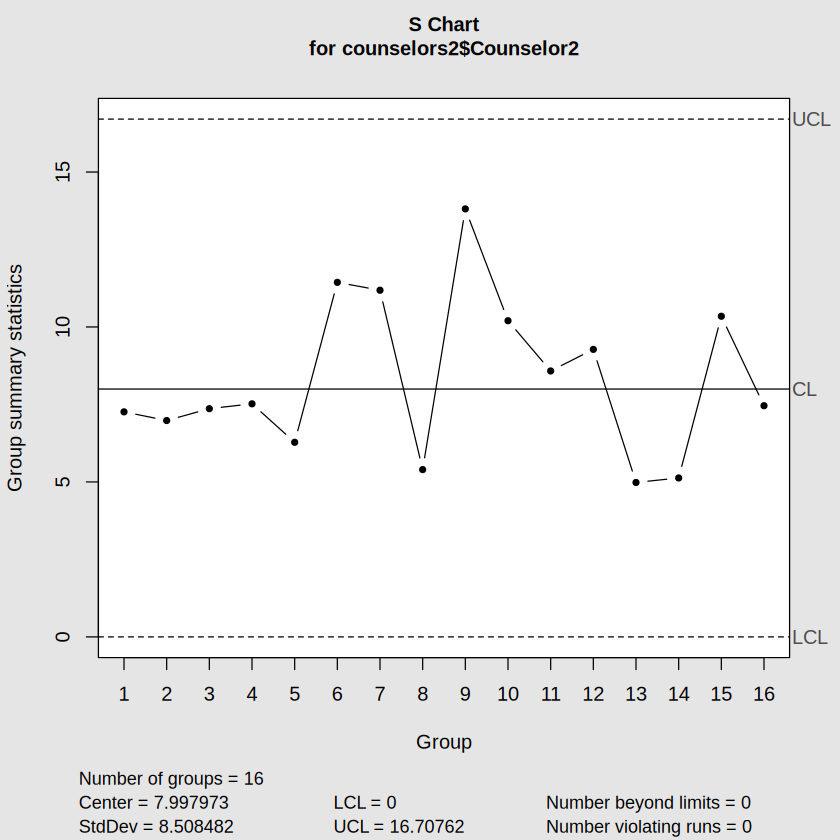

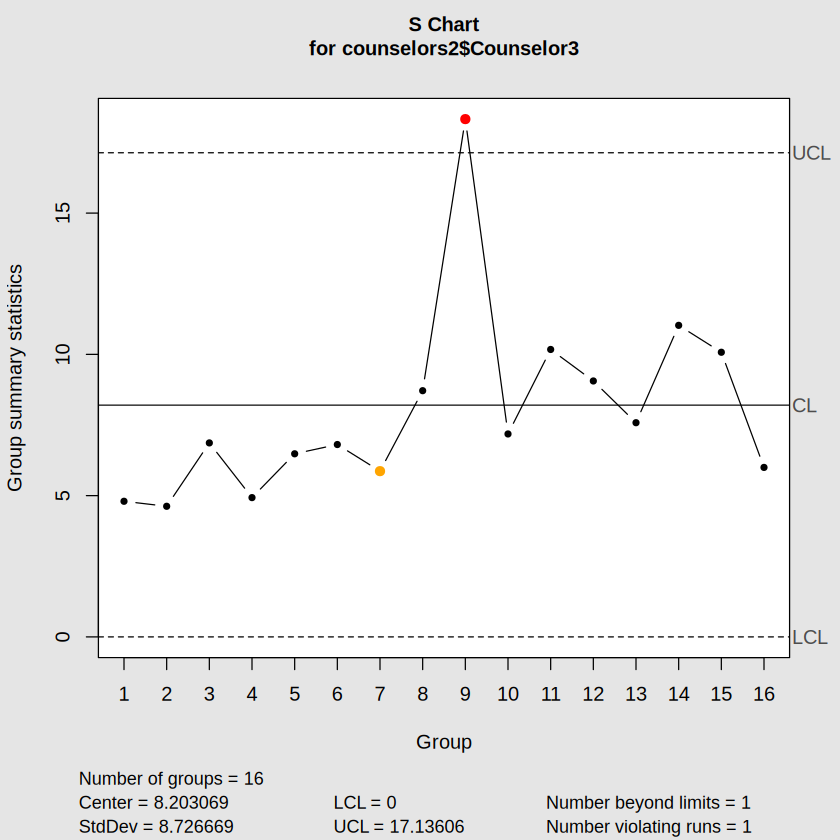

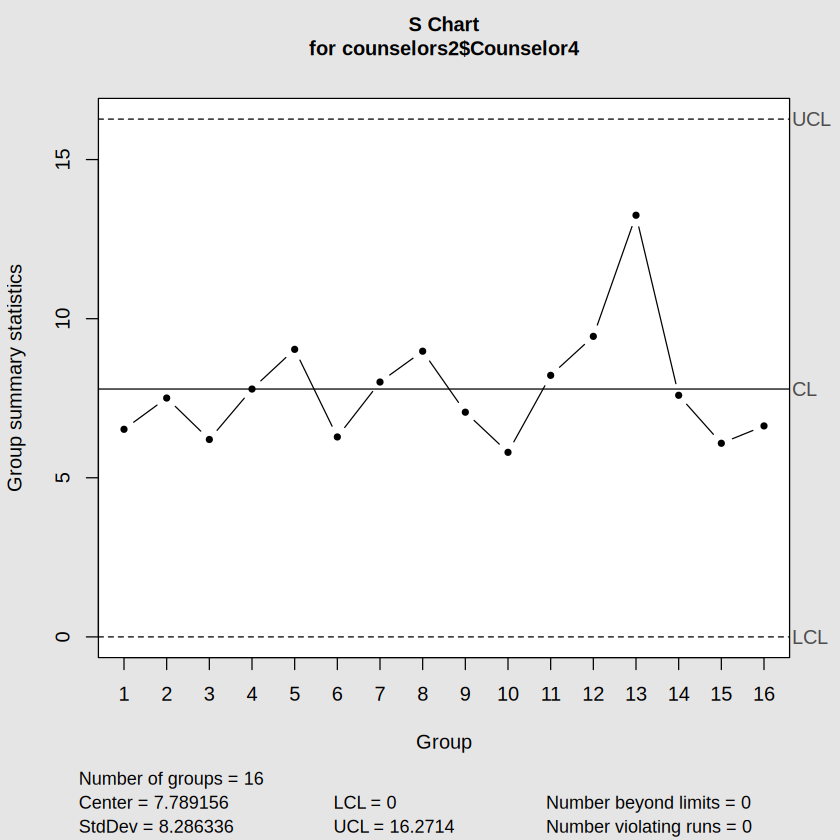

In [22]:
## Q6 Code ##
sheetnames2<- excel_sheets("Counselling_PhaseII.xlsx")
counselors2<- lapply(sheetnames2, FUN=function(x){
    d<- read_xlsx("Counselling_PhaseII.xlsx", sheet=x) %>%
    dplyr::select(-Week)

    return(d)
})

names(counselors2) <-paste("Counselor", 1:4, sep="")

counselors2["Counselor1"] |> glimpse()

## mqcc to Plot Chart ##

p2 <- mqcc(counselors2, type = "T2",
           center=t2$center,
           cov=t2$cov,
           limits=F,pred.limits=T,
           plot=T)

## OUT of Control- moving onto Posthoc and Shewhart's##
##c4 for n=5 is 0.9400#

c4<- 0.9400

counselor1_xbar<-t2$center[1]
counselor2_xbar<-t2$center[2]
counselor3_xbar<-t2$center[3]
counselor4_xbar<-t2$center[4]

counselor1_sd<-sqrt(t2$cov[1,1])/c4
counselor2_sd<-sqrt(t2$cov[2,2])/c4
counselor3_sd<-sqrt(t2$cov[3,3])/c4
counselor4_sd<-sqrt(t2$cov[4,4])/c4

## UCL & LCL ##
counselor1_ucl <- counselor1_xbar + 3*counselor1_sd
counselor1_lcl <- counselor1_xbar - 3*counselor1_sd

counselor2_ucl <- counselor2_xbar + 3*counselor2_sd
counselor2_lcl <- counselor2_xbar - 3*counselor2_sd

counselor3_ucl <- counselor3_xbar + 3*counselor3_sd
counselor3_lcl <- counselor3_xbar - 3*counselor3_sd

counselor4_ucl <- counselor4_xbar + 3*counselor4_sd
counselor4_lcl <- counselor4_xbar - 3*counselor4_sd

## Counselor 1 ##
xbar1<- qcc(rowMeans(counselors2$Counselor1),
            type="xbar",
            center=counselor1_xbar,
            sigma=counselor1_sd,
            sizes=5,
            limits=c(counselor1_lcl,counselor1_ucl))
## Counselor 2 ##
xbar2<- qcc(rowMeans(counselors2$Counselor2),
            type="xbar",
            center=counselor2_xbar,
            sigma=counselor2_sd,
            sizes=5,
            limits=c(counselor2_lcl,counselor2_ucl))
## Counselor 3 ##
xbar3<- qcc(rowMeans(counselors2$Counselor3),
            type="xbar",
            center=counselor3_xbar,
            sigma=counselor3_sd,
            sizes=5,
            limits=c(counselor3_lcl,counselor3_ucl))

## Counselor 4 ##
xbar4<- qcc(rowMeans(counselors2$Counselor4),
            type="xbar",
            center=counselor4_xbar,
            sigma=counselor4_sd,
            sizes=5,
            limits=c(counselor4_lcl,counselor4_ucl))

## S Charts ##

# Counselor 1 #
s1<- qcc (counselors2$Counselor1,
          type="S",
          std.dev=counselor1_sd,
          center=c4*counselor1_sd)
# Counselour 2 #
s2<- qcc (counselors2$Counselor2,
          type="S",
          std.dev=counselor2_sd,
          center=c4*counselor2_sd)

# Counselor 3 #
s3<- qcc (counselors2$Counselor3,
          type="S",
          std.dev=counselor3_sd,
          center=c4*counselor3_sd)

# Counselor 4 #
s4<- qcc (counselors2$Counselor4,
          type="S",
          std.dev=counselor4_sd,
          center=c4*counselor4_sd)

### Q7: What is the benefit of using a multivariate control chart over several separate univariate control charts? What is one limitation?

## Improve

### Q8: Based on your findings in Q6, briefly describe what intervention(s) you, as the director, might reasonably take regarding the counselor(s) flagged as out of control.

## Control

### Q9: It is reasonable to assume that this same monitoring situation could also be conceptualized as a **multiple stream process (MSP)** -- that is, treating the four counselors as independent, parallel processes rather than a single correlated multivariate one. Perform the same Phase I analysis as before, but using the Control Chart for Each Stream MSP technique ($L = 3.46$). Do we have evidence of statistical control?

In [ ]:
## Q9 Code ##

### Q10: Perform Phase II analysis using the Control Chart for Each Stream MSP technique. Do we still have evidence of statistical control? If not, which stream(s) (i.e., counselors) may be causing the out-of-control point(s)?

In [ ]:
## Q10 Code ##

### Q11: What is a difference between a multivariate process and a multiple stream process? Given what you found in Q4-Q10, which framing do you think is the more defensible choice for this specific scenario, and why?

### Q12: Provide an overview of your results that you, as the director, could bring to the university's Vice President of Student Affairs. What is the current status of The Owl's Nest program, and what actions (if any) have you taken or would you recommend?